<a href="https://colab.research.google.com/github/mahdisahad/WOA-Feature-Selection/blob/main/notebooks/04_WOA_Implementation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

print("Libraries imported successfully.")

Libraries imported successfully.


In [ ]:
PROJECT_PATH = Path("/content/drive/MyDrive/WOA_Project")

DATA_PATH = PROJECT_PATH / "datasets" / "colon_dataset.csv"

df = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully.")
print("Dataset shape:", df.shape)
print(df.head())

Dataset loaded successfully.
Dataset shape: (62, 2001)
      att_1     att_2     att_3     att_4     att_5     att_6     att_7  \
0  2.080750  1.099070  0.927763  1.029080 -0.130763  1.265460 -0.436286   
1  1.109460  0.786453  0.445560 -0.146323 -0.996316  0.555759  0.290734   
2 -0.676530  1.693100  1.559250  1.559980 -0.982179 -1.358510 -1.313990   
3  0.534396  1.677540  1.489030  0.778605 -0.183776 -1.116850 -1.487560   
4 -1.018900  0.511080  0.755641  1.013820  0.529899  0.160440 -0.087055   

      att_8     att_9    att_10  ...  att_1992  att_1993  att_1994  att_1995  \
0  0.728881  2.107980  1.359870  ... -0.138451  0.382957  0.876697 -0.216234   
1 -0.145259  1.132660  0.559093  ... -0.205499 -1.815370  0.324373 -1.296910   
2 -0.455067  0.295214  0.290694  ...  1.230160 -2.039000  2.366090  0.820656   
3 -0.579511  0.292683  1.345480  ... -0.593149 -4.440580  1.720710 -0.124617   
4  1.295290  0.458736  0.714082  ...  0.497628 -0.083921 -0.382733 -0.913389   

   att_1996  

In [ ]:
X = df.drop(columns=["class"])
y = df["class"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Remove duplicate features based only on training data
duplicate_columns = X_train.columns[
    X_train.T.duplicated()
].tolist()

X_train = X_train.drop(columns=duplicate_columns)
X_test = X_test.drop(columns=duplicate_columns)

print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)
print("Number of duplicate features removed:", len(duplicate_columns))
print("Number of available features:", X_train.shape[1])

Training data shape: (49, 1991)
Testing data shape: (13, 1991)
Number of duplicate features removed: 9
Number of available features: 1991


In [ ]:
# Number of available features
n_features = X_train.shape[1]

# WOA parameters
population_size = 10
max_iterations = 20

# Reproducibility
random_state = 42
rng = np.random.default_rng(random_state)

print("Number of features:", n_features)
print("Population size:", population_size)
print("Maximum iterations:", max_iterations)

Number of features: 1991
Population size: 10
Maximum iterations: 20


In [ ]:
# Initialize whale positions
lower_bound = -6
upper_bound = 6

positions = rng.uniform(
    lower_bound,
    upper_bound,
    size=(population_size, n_features)
)

print("Population shape:", positions.shape)
print("Minimum position:", positions.min())
print("Maximum position:", positions.max())

Population shape: (10, 1991)
Minimum position: -5.99984197732551
Maximum position: 5.999724245012331


In [ ]:
print("First whale position (first 10 features):")
print(positions[0, :10])

print("\nSecond whale position (first 10 features):")
print(positions[1, :10])

First whale position (first 10 features):
[ 3.28747258 -0.73345872  4.30317504  2.36841635 -4.86987183  5.70746822
  3.13367642  3.43277166 -4.46263641 -0.59536875]

Second whale position (first 10 features):
[ 2.09034231 -1.92316863 -5.14506627 -0.29633259  3.04524816 -2.5785312
 -1.97943747  4.14839281  0.24086295  4.11278363]


In [ ]:
def calculate_coefficients(iteration, max_iterations, rng):
    a = 2 - iteration * (2 / max_iterations)

    r1 = rng.random()
    r2 = rng.random()

    A = 2 * a * r1 - a
    C = 2 * r2

    return A, C

In [ ]:
A, C = calculate_coefficients(
    iteration=0,
    max_iterations=max_iterations,
    rng=rng
)

print("A:", A)
print("C:", C)

A: -1.8085171616054758
C: 0.8627235349193607


In [ ]:
def update_whale_positions(
    positions,
    best_position,
    iteration,
    max_iterations,
    rng,
    lower_bound=-6,
    upper_bound=6
):
    new_positions = np.zeros_like(positions)

    a = 2 - iteration * (2 / max_iterations)

    n_whales = positions.shape[0]

    for i in range(n_whales):

        X = positions[i].copy()

        r1 = rng.random()
        r2 = rng.random()

        A = 2 * a * r1 - a
        C = 2 * r2

        p = rng.random()

        if p < 0.5:

            if abs(A) < 1:

                # Encircling the best solution
                D = np.abs(C * best_position - X)
                new_position = best_position - A * D

            else:

                # Search for a random whale
                random_index = rng.integers(0, n_whales)
                random_position = positions[random_index]

                D = np.abs(C * random_position - X)
                new_position = random_position - A * D

        else:

            # Spiral movement
            b = 1
            l = rng.uniform(-1, 1)

            D_prime = np.abs(best_position - X)

            new_position = (
                D_prime * np.exp(b * l) * np.cos(2 * np.pi * l)
                + best_position
            )

        # Keep positions within the search boundaries
        new_positions[i] = np.clip(
            new_position,
            lower_bound,
            upper_bound
        )

    return new_positions

فعلاً چون هنوز تابع فیتنس واقعی را تعریف نکرده‌ایم، نهنگ اول را به‌صورت آزمایشی به‌عنوان بهترین موقعیت در نظر می‌گیریم. این فقط یک آزمایش فنی است

In [ ]:
test_best_position = positions[0].copy()

updated_positions = update_whale_positions(
    positions=positions,
    best_position=test_best_position,
    iteration=0,
    max_iterations=max_iterations,
    rng=rng
)

print("Updated population shape:", updated_positions.shape)
print("Minimum updated position:", updated_positions.min())
print("Maximum updated position:", updated_positions.max())

print(
    "All positions within bounds:",
    np.all(updated_positions >= lower_bound)
    and np.all(updated_positions <= upper_bound)
)

Updated population shape: (10, 1991)
Minimum updated position: -6.0
Maximum updated position: 6.0
All positions within bounds: True


In [ ]:
def sigmoid(x):
    return 1 / (1 + np.exp(-np.clip(x, -50, 50)))


def continuous_to_binary(position, rng):
    probabilities = sigmoid(position)

    random_values = rng.random(size=position.shape)

    binary_position = (random_values < probabilities).astype(int)

    return binary_position

In [ ]:
test_binary = continuous_to_binary(
    positions[0],
    rng
)

print("Binary vector shape:", test_binary.shape)
print("First 20 values:", test_binary[:20])
print("Number of selected features:", test_binary.sum())
print("Number of unselected features:", len(test_binary) - test_binary.sum())

Binary vector shape: (1991,)
First 20 values: [1 0 1 1 0 1 1 1 0 1 1 1 1 1 0 0 1 0 1 1]
Number of selected features: 976
Number of unselected features: 1015


In [ ]:
assert test_binary.shape == (n_features,)
assert set(np.unique(test_binary)).issubset({0, 1})
assert test_binary.sum() >= 0

print("Binary conversion test passed.")

Binary conversion test passed.


In [ ]:
# Define the classification model
classifier = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(
        class_weight="balanced",
        max_iter=5000,
        random_state=42
    ))
])

# Define cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Fitness parameters
alpha = 0.9

print("Classifier and cross-validation are ready.")
print("Alpha:", alpha)
print("Number of CV folds:", cv.get_n_splits())

Classifier and cross-validation are ready.
Alpha: 0.9
Number of CV folds: 5


In [ ]:
def fitness_function(
    binary_position,
    X_train,
    y_train,
    classifier,
    cv,
    alpha=0.9
):
    # Convert input to a NumPy array
    binary_position = np.asarray(binary_position)

    # Find selected feature indices
    selected_indices = np.where(binary_position == 1)[0]

    # Count selected features
    n_selected = len(selected_indices)

    # Reject solutions with no selected features
    if n_selected == 0:
        return 1.0

    # Select only the chosen features
    X_selected = X_train.iloc[:, selected_indices]

    # Evaluate classification performance using cross-validation
    cv_scores = cross_val_score(
        classifier,
        X_selected,
        y_train,
        cv=cv,
        scoring="f1_macro"
    )

    mean_f1 = cv_scores.mean()

    # Calculate feature selection ratio
    feature_ratio = n_selected / X_train.shape[1]

    # Calculate final fitness
    fitness = (
        alpha * (1 - mean_f1)
        + (1 - alpha) * feature_ratio
    )

    return fitness

In [ ]:
all_features = np.ones(n_features, dtype=int)

fitness_all = fitness_function(
    all_features,
    X_train,
    y_train,
    classifier,
    cv,
    alpha
)

print("Fitness with all features:", fitness_all)

Fitness with all features: 0.2409565434565434


In [ ]:
fitness_random = fitness_function(
    test_binary,
    X_train,
    y_train,
    classifier,
    cv,
    alpha
)

print("Number of selected features:", test_binary.sum())
print("Fitness with random features:", fitness_random)

Number of selected features: 976
Fitness with random features: 0.18997713612354494


In [ ]:
empty_solution = np.zeros(n_features, dtype=int)

fitness_empty = fitness_function(
    empty_solution,
    X_train,
    y_train,
    classifier,
    cv,
    alpha
)

print("Fitness with no selected features:", fitness_empty)

Fitness with no selected features: 1.0


In [ ]:
assert 0 <= fitness_all <= 1
assert 0 <= fitness_random <= 1
assert fitness_empty == 1.0

print("All fitness tests passed.")

All fitness tests passed.


In [ ]:
def population_to_binary(positions, rng):
    probabilities = sigmoid(positions)

    random_values = rng.random(size=positions.shape)

    binary_population = (
        random_values < probabilities
    ).astype(int)

    return binary_population

In [ ]:
test_population_binary = population_to_binary(
    positions,
    rng
)

print("Binary population shape:", test_population_binary.shape)
print("Unique values:", np.unique(test_population_binary))
print("Selected features in first whale:", test_population_binary[0].sum())

Binary population shape: (10, 1991)
Unique values: [0 1]
Selected features in first whale: 1032


In [ ]:
def binary_woa(
    X_train,
    y_train,
    classifier,
    cv,
    population_size=10,
    max_iterations=20,
    alpha=0.9,
    lower_bound=-6,
    upper_bound=6,
    random_state=42
):
    rng = np.random.default_rng(random_state)

    n_features = X_train.shape[1]

    # 1. Initialize continuous whale positions
    positions = rng.uniform(
        lower_bound,
        upper_bound,
        size=(population_size, n_features)
    )

    # 2. Convert initial population to binary
    binary_population = population_to_binary(
        positions,
        rng
    )

    # 3. Evaluate initial population
    fitness_values = np.array([
        fitness_function(
            binary_population[i],
            X_train,
            y_train,
            classifier,
            cv,
            alpha
        )
        for i in range(population_size)
    ])

    # 4. Find initial global best
    best_index = np.argmin(fitness_values)

    best_fitness = fitness_values[best_index]
    best_position = positions[best_index].copy()
    best_binary_solution = binary_population[best_index].copy()

    convergence_curve = [best_fitness]

    # 5. Main WOA iterations
    for iteration in range(max_iterations):

        # Update continuous positions
        positions = update_whale_positions(
            positions=positions,
            best_position=best_position,
            iteration=iteration,
            max_iterations=max_iterations,
            rng=rng,
            lower_bound=lower_bound,
            upper_bound=upper_bound
        )

        # Convert updated positions to binary
        binary_population = population_to_binary(
            positions,
            rng
        )

        # Evaluate new population
        fitness_values = np.array([
            fitness_function(
                binary_population[i],
                X_train,
                y_train,
                classifier,
                cv,
                alpha
            )
            for i in range(population_size)
        ])

        # Find best candidate in current iteration
        current_best_index = np.argmin(fitness_values)
        current_best_fitness = fitness_values[current_best_index]

        # Update global best if improvement is found
        if current_best_fitness < best_fitness:

            best_fitness = current_best_fitness

            best_position = positions[current_best_index].copy()

            best_binary_solution = (
                binary_population[current_best_index].copy()
            )

        # Store best fitness so far
        convergence_curve.append(best_fitness)

        print(
            f"Iteration {iteration + 1}/{max_iterations} "
            f"| Best Fitness: {best_fitness:.6f} "
            f"| Selected Features: {best_binary_solution.sum()}"
        )

    return (
        best_binary_solution,
        best_fitness,
        convergence_curve
    )

In [ ]:
best_solution, best_fitness, convergence_curve = binary_woa(
    X_train=X_train,
    y_train=y_train,
    classifier=classifier,
    cv=cv,
    population_size=population_size,
    max_iterations=max_iterations,
    alpha=alpha,
    lower_bound=lower_bound,
    upper_bound=upper_bound,
    random_state=42
)

Iteration 1/20 | Best Fitness: 0.173955 | Selected Features: 657
Iteration 2/20 | Best Fitness: 0.173955 | Selected Features: 657
Iteration 3/20 | Best Fitness: 0.171233 | Selected Features: 250
Iteration 4/20 | Best Fitness: 0.146180 | Selected Features: 104
Iteration 5/20 | Best Fitness: 0.146180 | Selected Features: 104
Iteration 6/20 | Best Fitness: 0.126651 | Selected Features: 109
Iteration 7/20 | Best Fitness: 0.126651 | Selected Features: 109
Iteration 8/20 | Best Fitness: 0.126651 | Selected Features: 109
Iteration 9/20 | Best Fitness: 0.126651 | Selected Features: 109
Iteration 10/20 | Best Fitness: 0.126651 | Selected Features: 109
Iteration 11/20 | Best Fitness: 0.126651 | Selected Features: 109
Iteration 12/20 | Best Fitness: 0.126651 | Selected Features: 109
Iteration 13/20 | Best Fitness: 0.126651 | Selected Features: 109
Iteration 14/20 | Best Fitness: 0.126651 | Selected Features: 109
Iteration 15/20 | Best Fitness: 0.126651 | Selected Features: 109
Iteration 16/20 | B

In [ ]:
print("Best Fitness:", best_fitness)

print("Best solution shape:", best_solution.shape)

print("Number of selected features:", best_solution.sum())

print(
    "Number of unselected features:",
    len(best_solution) - best_solution.sum()
)

print("Unique values:", np.unique(best_solution))

Best Fitness: 0.10702141780871065
Best solution shape: (1991,)
Number of selected features: 112
Number of unselected features: 1879
Unique values: [0 1]


In [ ]:
assert best_solution.shape == (n_features,)
assert set(np.unique(best_solution)).issubset({0, 1})
assert best_solution.sum() > 0

print("Best solution validation passed.")

Best solution validation passed.


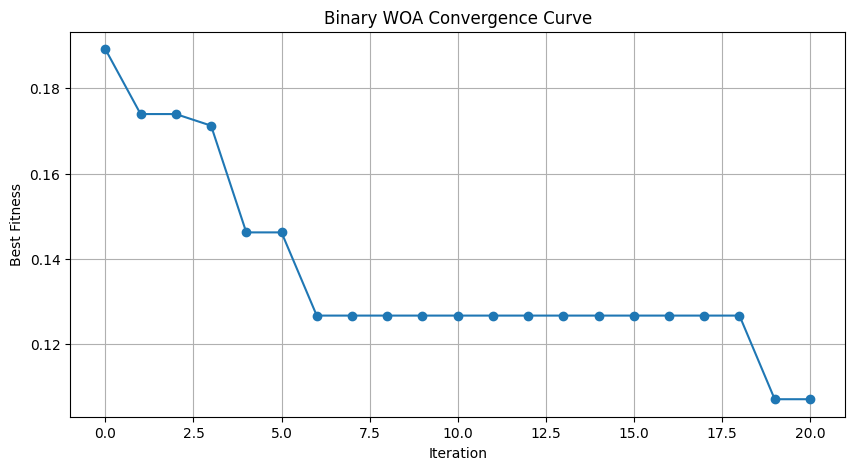

In [ ]:
plt.figure(figsize=(10, 5))

plt.plot(
    range(len(convergence_curve)),
    convergence_curve,
    marker="o"
)

plt.xlabel("Iteration")
plt.ylabel("Best Fitness")
plt.title("Binary WOA Convergence Curve")

plt.grid(True)
plt.show()

In [ ]:
RESULTS_PATH = PROJECT_PATH / "results"
RESULTS_PATH.mkdir(parents=True, exist_ok=True)

In [ ]:
selected_features = X_train.columns[
    best_solution == 1
].tolist()

print("First 20 selected features:")
print(selected_features[:20])

print("Total selected features:", len(selected_features))

First 20 selected features:
['att_7', 'att_8', 'att_90', 'att_110', 'att_131', 'att_149', 'att_157', 'att_195', 'att_197', 'att_199', 'att_202', 'att_286', 'att_288', 'att_301', 'att_304', 'att_312', 'att_341', 'att_344', 'att_382', 'att_387']
Total selected features: 112


In [ ]:
selected_features_df = pd.DataFrame({
    "Feature": selected_features
})

selected_features_df.to_csv(
    RESULTS_PATH / "woa_selected_features.csv",
    index=False
)

convergence_df = pd.DataFrame({
    "Iteration": range(len(convergence_curve)),
    "Best_Fitness": convergence_curve
})

convergence_df.to_csv(
    RESULTS_PATH / "woa_convergence.csv",
    index=False
)

print("Results saved successfully.")

Results saved successfully.
